# [레퍼런스] 시계열 복습

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## 0. 레퍼런스 쓰는 법

<div style="background:#FFFFFF;color:#000000;padding:40px;border-radius:12px;border:1px solid #E6E6E6;border-left:4px solid #051C2C">
<div style="font-size:0.9em;color:#656565">AI 데이터 인텔리전스 전문가 과정 · 시계열 예측</div>
<h1 style="color:#000000;margin:10px 0">시계열 복습</h1>
<div style="font-size:1.05em;color:#656565">1～5일차 복습 카드 다섯 장과 이상 탐지 짧은 카드, 모듈 결정 규칙 표 한 장</div>
</div>

## 0. 레퍼런스 쓰는 법

복습 퀴즈와 프롬프트 문제를 풀다가 필요한 날의 카드를 찾아봅니다. 1～5일차 카드는 모듈 첫째 날부터 다섯째 날까지 날마다 한 장입니다. 카드마다 결정 질문, 그 답을 푸는 짧은 설명과 그림, 결론, 기억할 식·지표, 쓰는 코드, 흔한 실수를 같은 순서로 적었습니다.

카드 끝의 「다시 볼 곳」에는 더 자세한 설명과 그림을 볼 수 있는 제목을 적었습니다. 이상 탐지 카드는 복습 프로젝트 미션 2 의 `이상` 열을 만드는 규칙이고 결론 뒤에 그림 한 장을 두었습니다. 마지막 표는 다섯 날의 결정 규칙을 한 장에 모은 것입니다.

## 1. 1일차 — 분해와 정상성

**결정 질문** 이 대여 수요의 계절 주기는 몇 시간일까요? 이 계열을 그대로 예측 모형에 입력해도 될까요?

아래 첫째 그림은 같은 대여 수요를 시간당 수요와 일 수요로 집계해 같은 순서로 준비한 과정입니다. 계절성 강도로 계절 주기를 정하고, ADF 와 KPSS 를 함께 적용한 뒤, 두 검정이 모두 정상 쪽이 될 때까지만 차분합니다. 두 검정의 결론 조합은 아래 둘째 그림의 네 상자 가운데 하나로 읽습니다.

예를 들어 화요일 18시 대여가 1,200대, 월요일 18시가 1,000대라면 24시간 계절차분 값은 $1{,}200 - 1{,}000 = 200$대입니다. 매일 18시마다 되풀이되는 수준은 빠지고, 전날 같은 시각보다 늘어난 200대만 남습니다.

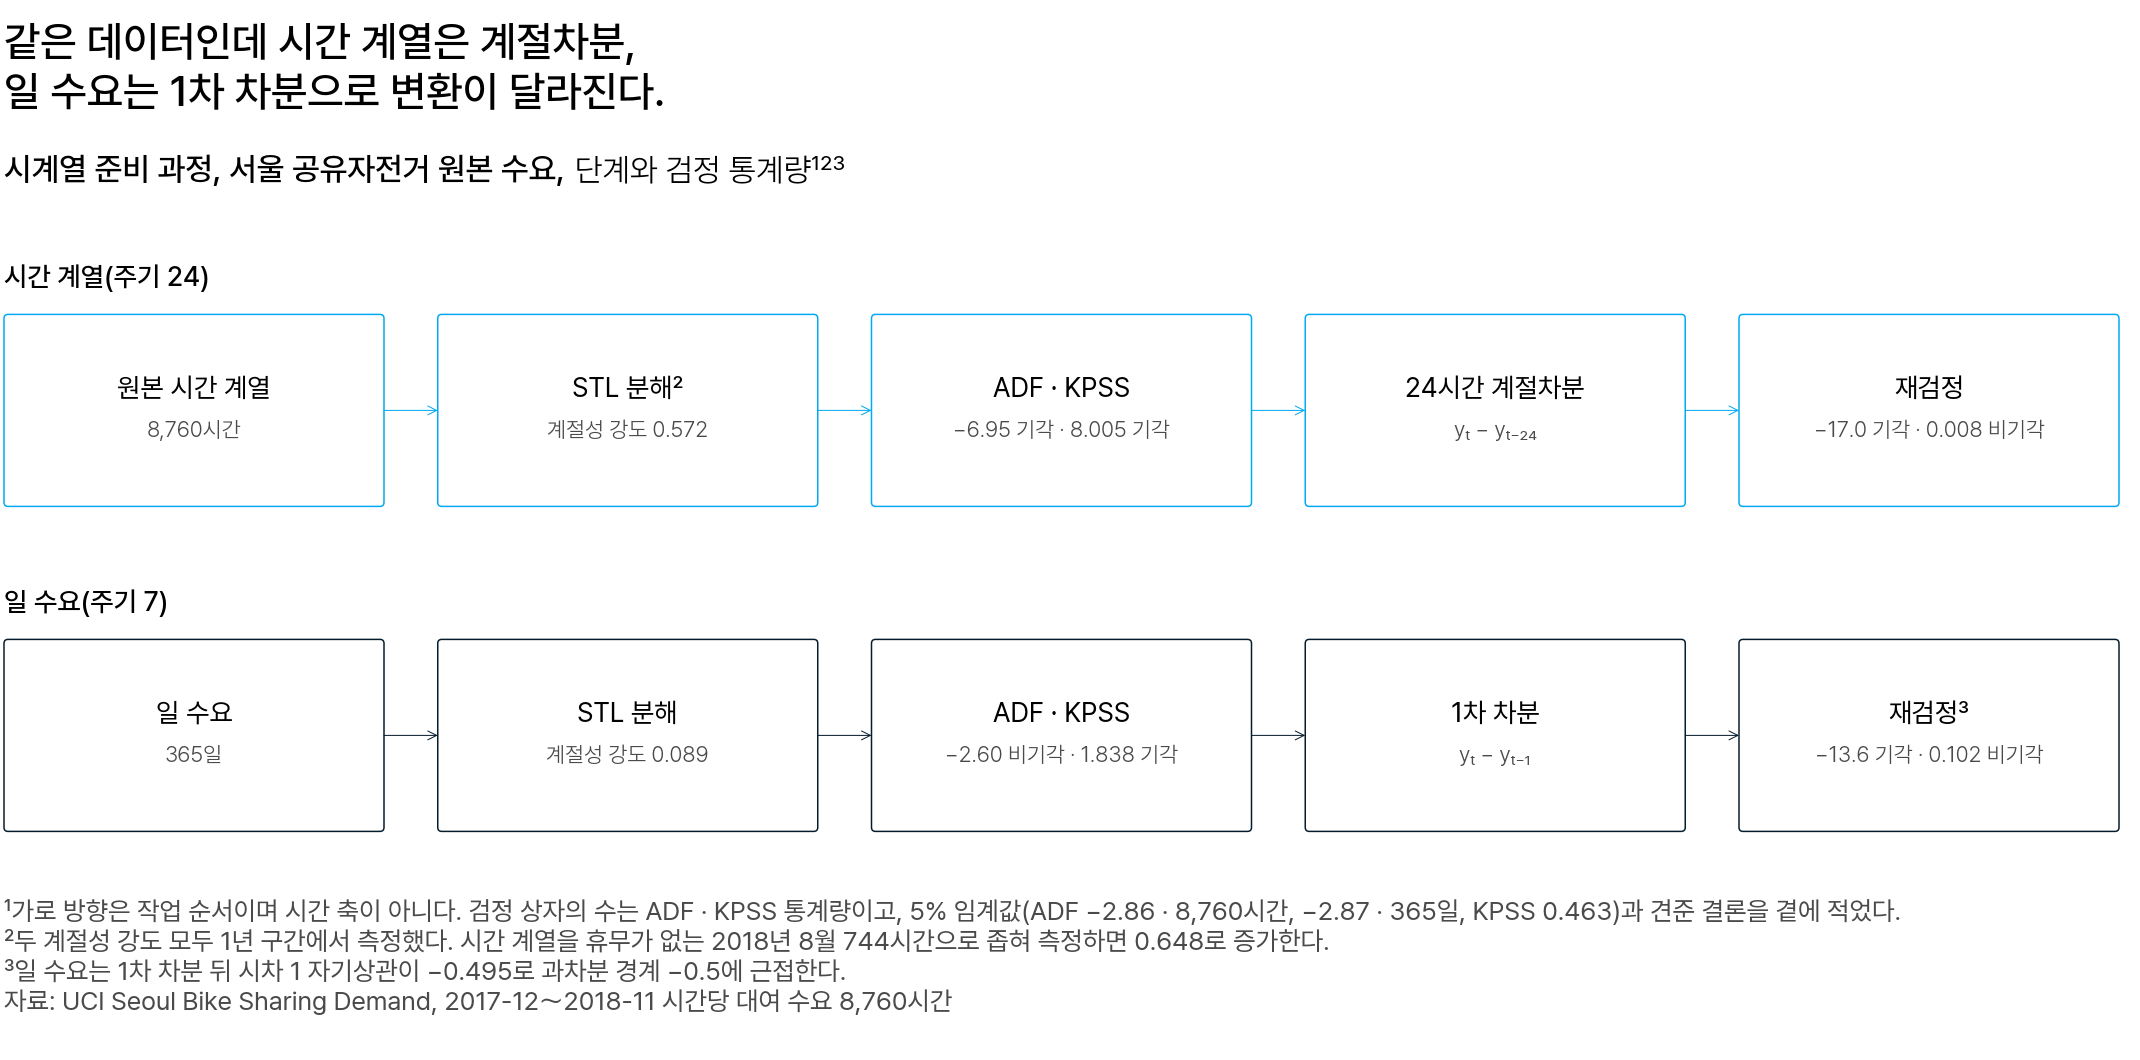

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 같은 대여 수요를 시간당과 일 단위로 집계해 준비한 과정. 위 줄의 시간당 수요는 24시간 계절차분 1회 뒤, 아래 줄의 일 수요는 1차 차분 1회 뒤에 ADF·KPSS 가 둘 다 정상 쪽이 된다</em></p>

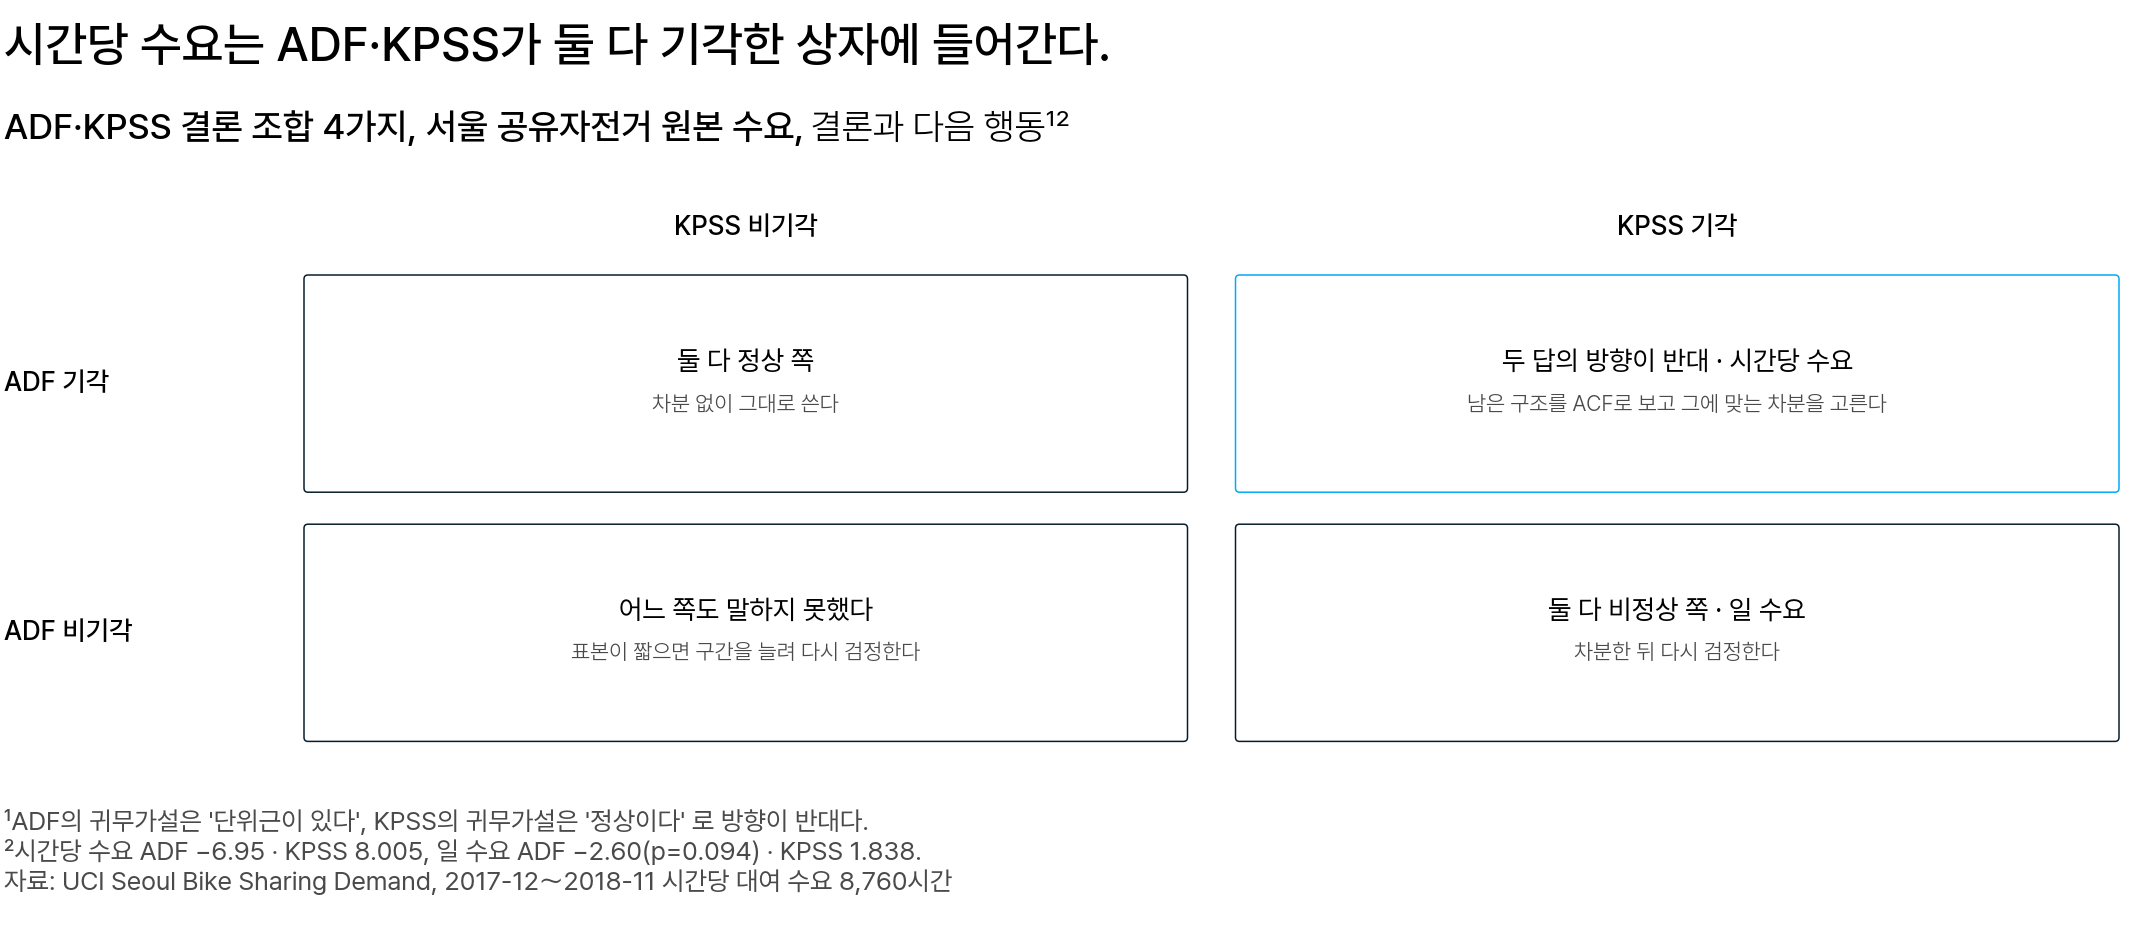

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ ADF·KPSS 결론 조합 4가지. 시간당 수요는 두 답이 엇갈린 오른쪽 위 상자, 일 수요는 둘 다 비정상 쪽인 오른쪽 아래 상자에 들어간다</em></p>

**결론**

- 가장 강한 계절성은 하루 주기(시각)이고, 계절 주기는 $m = 24$ 입니다. 1년에서 측정한 계절성 강도가 주기 24 는 0.5715, 주기 7 은 0.0894 입니다. 요일 차이는 약하지만 남습니다(3일차 카드의 잔차 진단).
- 원본 시간당 수요는 그대로 입력하지 않습니다. ADF −6.9470 은 단위근 가설을, KPSS 8.0051 은 정상 가설을 기각해 두 검정의 답이 엇갈립니다.
- 시간당 수요는 24시간 계절차분을 1회 합니다($D = 1$). 1차 차분은 하지 않습니다($d = 0$). 계절차분 뒤에는 ADF −17.0150 · KPSS 0.0083 으로 두 검정이 모두 정상 쪽입니다.
- 계절차분은 평균의 차이를 지우지만 산포 차이는 남깁니다. 석 달 묶음마다 계절차분 값의 표준편차가 115.6～651.8 로 다릅니다.
- 일 수요 365일은 1차 차분을 1회($d = 1$) 합니다. 원본은 ADF −2.60 · KPSS 1.838 로 둘 다 비정상 쪽입니다. 차분 뒤에는 ADF −13.6 · KPSS 0.102 로 둘 다 정상 쪽입니다.

**기억할 식·지표**

$$
F_S = \max\left(0,\; 1 - \frac{\operatorname{Var}(R_t)}{\operatorname{Var}(S_t + R_t)}\right)
$$

- $F_S$ : 계절성 강도입니다. 추세를 뺀 나머지 변동 가운데 계절성분이 설명하는 비중이고, 1 에 가까울수록 계절성분이 큽니다
- $R_t$ : 잔차입니다
- $S_t + R_t$ : 계절성분과 잔차의 합, 곧 추세를 뺀 나머지입니다. 분모에 추세는 들어가지 않습니다

$$
\Delta_m y_t = y_t - y_{t-m}
$$

- $\Delta_m y_t$ : 계절차분한 값입니다. 한 주기 전 같은 시각의 값을 뺍니다
- $m$ : 계절 주기입니다. 시간당 수요는 $m = 24$ 라 1년 8,760시간의 맨 앞 24시간이 빠져 8,736개가 남습니다

두 검정은 통계량을 5% 임계값과 견줍니다. ADF 는 임계값(8,760시간에서 −2.86)보다 더 음수이면 정상 쪽이고, KPSS 는 0.463 보다 작으면 정상 쪽입니다.

**쓰는 코드**

- `STL(daily_c, period=7, robust=True).fit()`: 일 수요를 주기 7 로 분해합니다. `robust=True` 는 휴무처럼 튄 값을 추세가 아니라 잔차로 보냅니다
- `adfuller(x, autolag="AIC")` · `kpss(x, regression="c", nlags="auto")`: 두 정상성 검정을 함께 적용합니다
- `x.diff(24).dropna()`: 24시간 계절차분입니다

**흔한 실수**

- ADF 와 KPSS 를 똑같이 「`p값 < ALPHA` 이면 정상」으로 읽는 실수입니다. 두 검정은 귀무가설이 반대라 KPSS 결론이 정확히 반대가 됩니다. ADF 기각은 정상 쪽 증거, KPSS 기각은 비정상 쪽 증거이므로 무엇을 기각했는지 결론 문구에 적습니다.
- 이미 정상인 계열을 한 번 더 차분하는 실수입니다. 분산이 커지고 시차 1 자기상관이 −0.5 근처로 내려갑니다. 1일차 이론의 랜덤워크 예에서 차분 1회의 분산 0.983 이 2회에서 1.955 로 커지고, 시차 1 자기상관은 −0.502 입니다. 다만 차분 전 결론이 비정상이었다면 −0.5 가 나와도 그 차분은 필요했던 것입니다.

**다시 볼 곳**

- 1일차 이론 「4. 계절성 강도: 주기 24와 주기 7의 비교」
- 1일차 이론 「7. ADF와 KPSS: 귀무가설이 반대인 두 검정」
- 1일차 이론 「8. 차분: 비정상을 정상으로 바꾸는 변환」

## 2. 2일차 — ARIMA 모델링 · 차수 결정

**결정 질문** 내일 9시 수요를 맞히려면 지난 값과 지난 오차항을 각각 몇 개씩 식에 써야 할까요?

아래 첫째 그림의 부분자기상관은 시차 1·2·3 이 경계선 ±0.11 밖입니다. 시차 2·3 은 경계선을 조금 넘을 뿐이고 시차 1 이 0.87 로 훨씬 커서, $p$ 를 1～2 로 둔 후보를 만듭니다. 시차 10 뒤로 경계선 밖에 나온 막대(시차 11 의 −0.37, 25 의 0.33 등)는 계절 항으로 설명할 상관이라 $p$ 후보에 쓰지 않습니다.

서울 공유자전거 학습 336시간 후보 넷의 AIC 는 (1, 0, 1) 이 4,269.29 로 가장 낮습니다. (2, 0, 1) 은 4,269.78 로 차이가 0.49 이고, 2 이하라 계수가 하나 적은 쪽을 고릅니다. (1, 0, 0) 은 4,275.16 으로 5.87 높아, 지난 오차항을 쓰는 항 하나를 더한 쪽이 낫다고 말할 수 있습니다.

규칙대로 $p = 3$ 으로 읽은 (3, 0, 0) 은 4,269.04 로 0.25 낮습니다. 그래도 차이가 2 이하라 계수가 적은 (1, 0, 1) 이 남습니다.

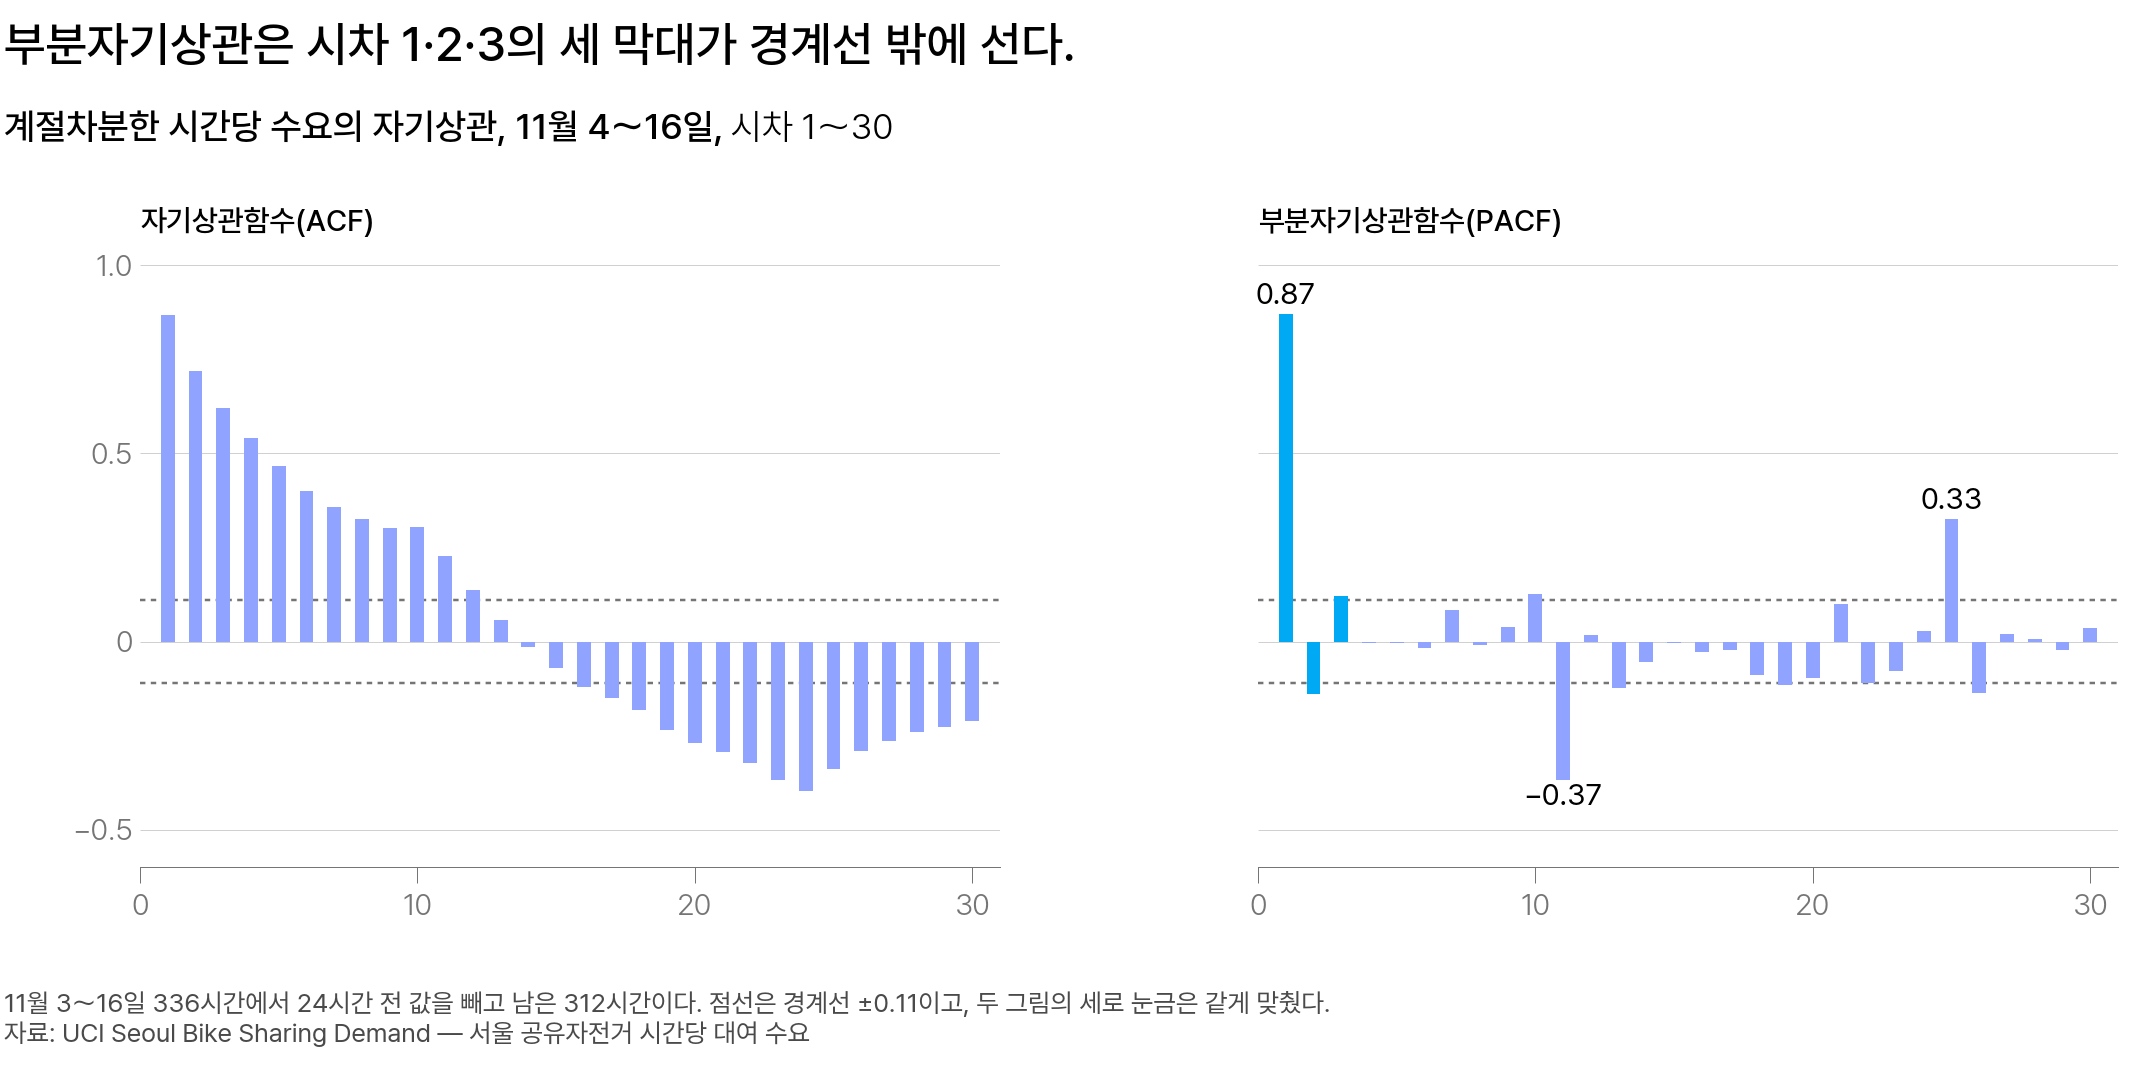

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 계절차분한 312시간의 자기상관과 부분자기상관. 왼쪽 자기상관은 시차 1 의 0.87 에서 천천히 줄어 시차 13 에 점선 ±0.11 안으로 들어오고, 오른쪽 하늘색 막대는 부분자기상관의 시차 1·2·3 이다</em></p>

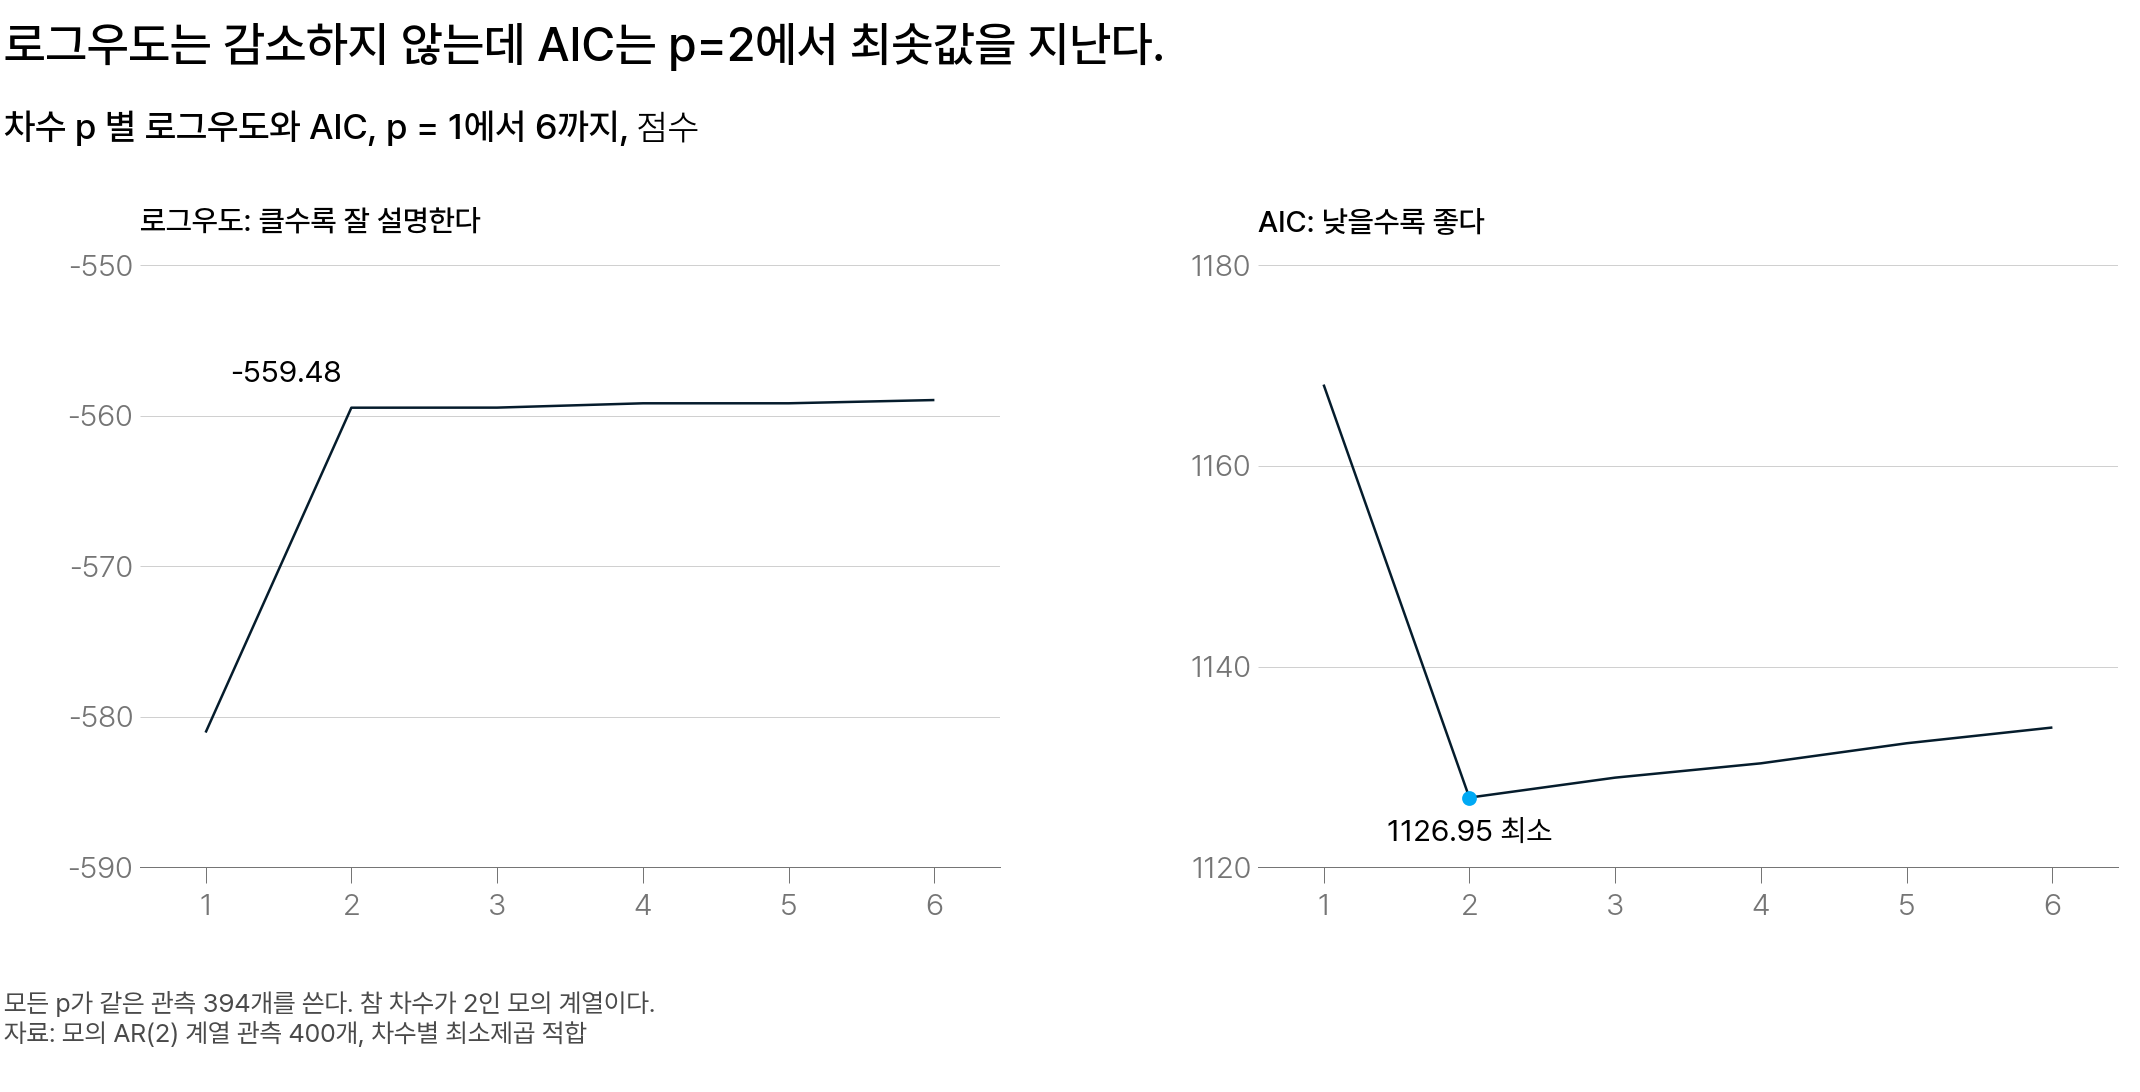

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 참 차수가 2 인 모의 계열의 차수 p 별 로그우도와 AIC. 왼쪽 로그우도는 p = 2 뒤로 거의 평평하게 늘고, 오른쪽 AIC 는 p = 2 에서 최솟값 1126.95 를 지난 뒤 다시 올라간다</em></p>

**결론**

- 자기상관 그림은 차수 후보를 서너 개로 좁히는 데까지 쓰고, 확정은 AIC 로 합니다.
- `auto_arima` 가 고른 차수도 (1, 0, 1) 로, 학습 336시간 후보 넷 가운데 AIC 가 가장 낮은 차수와 같습니다.
- 실습 1,848시간 표의 1위는 (1,0,1)(0,1,0,24) 로 AIC 25,209.34 입니다. 2위는 (2,0,1)(0,1,0,24) 로 25,211.16 입니다. 반올림 전 값의 차이가 1.83 으로 2 이하라, 항이 적은 (1,0,1)(0,1,0,24) 를 공식 차수로 둡니다.
- AIC 가 낮은 차수가 예측에서도 앞선다는 보장은 없습니다. 11월 17일 24시간의 평균 절대 오차(MAE)는 (1, 0, 1) 이 252대/시간입니다. 계수가 하나도 없는 랜덤워크 ARIMA(0, 1, 0) 은 247대/시간으로 더 작습니다. 하루 24시각만으로는 이 5대 차이가 그날의 사정인지 모형의 차이인지 판단할 수 없습니다.
- 하루 합계 365일 계열은 시간당 배차의 근거가 되지 않습니다. 계절 차수 없이 `auto_arima` 를 적용하면 $d = 1$, AIC 7,460.94 가 나오지만 예측 1개가 하루 합계 하나입니다.

**기억할 식·지표**

$$
\text{AIC} = 2k - 2\ln \hat{L}
$$

- $k$ : 추정한 모수의 개수입니다. ARIMA(p, d, q) 는 계수 $p + q$ 개에 상수항과 오차항의 분산을 더해 $k = p + q + 2$ 입니다
- $2k$ : 페널티 항입니다. 모수 하나마다 2 씩 더합니다
- $\ln \hat{L}$ : 적합이 고른 계수에서의 로그우도입니다. 클수록 자료를 잘 설명한 것입니다

AIC 는 낮을수록 좋고, 차분 횟수 $d$ 가 같은 모형끼리만 비교합니다. 차이가 2 이하이면 우열을 정하지 않고 항이 적은 쪽을 고릅니다.

$$
\pm \frac{1.96}{\sqrt{T}}
$$

- $T$ : 자료 수입니다. 자기상관 막대가 이 경계선 밖이면 그 시차의 자기상관을 0 이 아니라고 읽습니다

계절차분한 312시간이면 경계선은 $\pm 1.96/\sqrt{312} = \pm 0.11$ 입니다.

**쓰는 코드**

- `model = pm.auto_arima(demand, seasonal=True, m=24, information_criterion="aic", stepwise=True)`: 차수를 탐색합니다(`import pmdarima as pm`). 고른 차수는 `model.order` 와 `model.seasonal_order` 로 읽습니다
- `SARIMAX(y_train, order=(p, D_LEVEL, q), seasonal_order=(0, D_SEASONAL, 0, M)).fit(disp=False).aic`: 후보 한 조합의 AIC 입니다. `itertools.product(P_GRID, Q_GRID)` 로 6조합을 돕니다
- `pd.DataFrame(rows).sort_values("AIC")`: AIC 가 낮은 순으로 정렬합니다

**흔한 실수**

- `order` 튜플의 가운데 값(1차 차분 횟수 $d$)을 1 로 적는 실수입니다. 1일차에 정한 $d = 0$ 과 어긋나 행마다 우도를 계산한 계열이 달라지고, AIC 를 서로 비교할 수 없게 됩니다. 1위 행 하나만 가운데 값을 1 로 적합해도 AIC 가 25,368.86 으로 올라 1위가 (2,0,1) 로 바뀝니다.
- 로그우도가 가장 큰 차수를 고르는 실수입니다. 로그우도는 항을 늘려도 줄지 않아, 이 기준이면 항이 가장 많은 모형이 늘 뽑힙니다. 2일차 이론의 참 차수 2 인 AR 계열에서 로그우도가 가장 큰 차수는 $p = 6$ 이고, AIC 가 가장 낮은 차수는 $p = 2$ 입니다.

**다시 볼 곳**

- 2일차 이론 「3. AR·MA·차분의 결합 — ARIMA(p, d, q)」
- 2일차 이론 「4. 차수 후보를 좁히는 자기상관함수」
- 2일차 이론 「5. 후보 선택 기준 AIC 와 `auto_arima`」

## 3. 3일차 — SARIMA · 잔차 진단 · 예측구간

**결정 질문** 계절 항을 더한 SARIMA 의 예측을 다음 주 시간당 배차 숫자로 그대로 전달해도 될까요?

배차 숫자로 넘길 예측은 같은 시간을 채점했을 때 베이스라인(baseline)보다 덜 빗나가는 모형에서 가져옵니다. 베이스라인은 1주일 전 같은 시각 값을 그대로 예측으로 쓰는 계절 나이브 168 입니다. SARIMA 는 계절 주기를 24 하나만 받아, 토요일 예측에도 평일 출근 수요가 섞입니다. 아래 첫째 그림의 토요일 8시에 SARIMA 예측은 1,348대, 실측은 530대라 818대를 빗나갑니다.

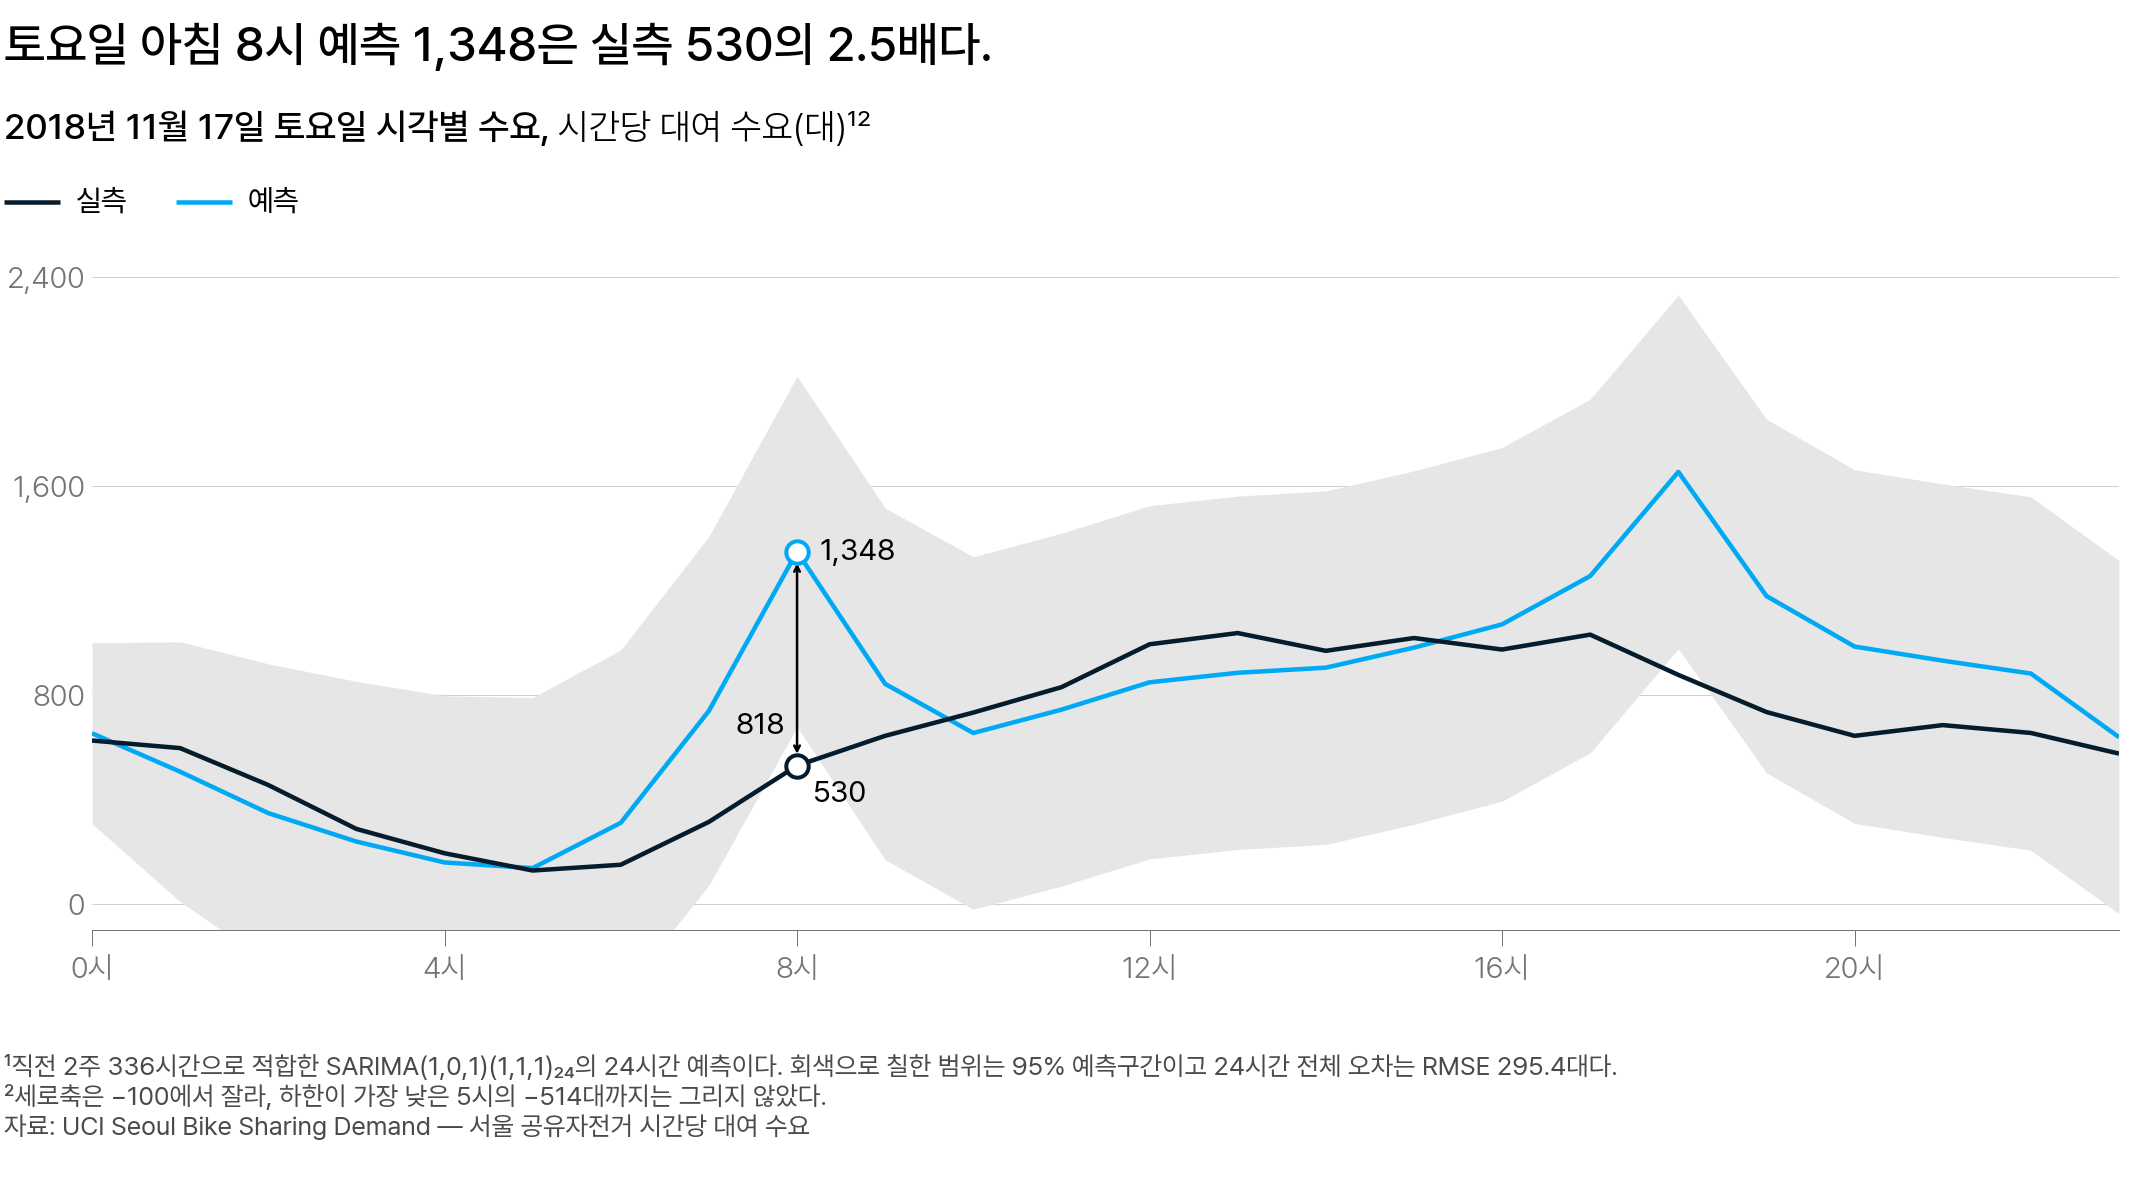

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 11월 17일 토요일 24시간의 실측과 SARIMA 예측. 남색이 실측, 하늘색이 예측, 회색이 95% 예측구간이고, 예측은 8시와 18시 무렵에 실측보다 크게 높다</em></p>

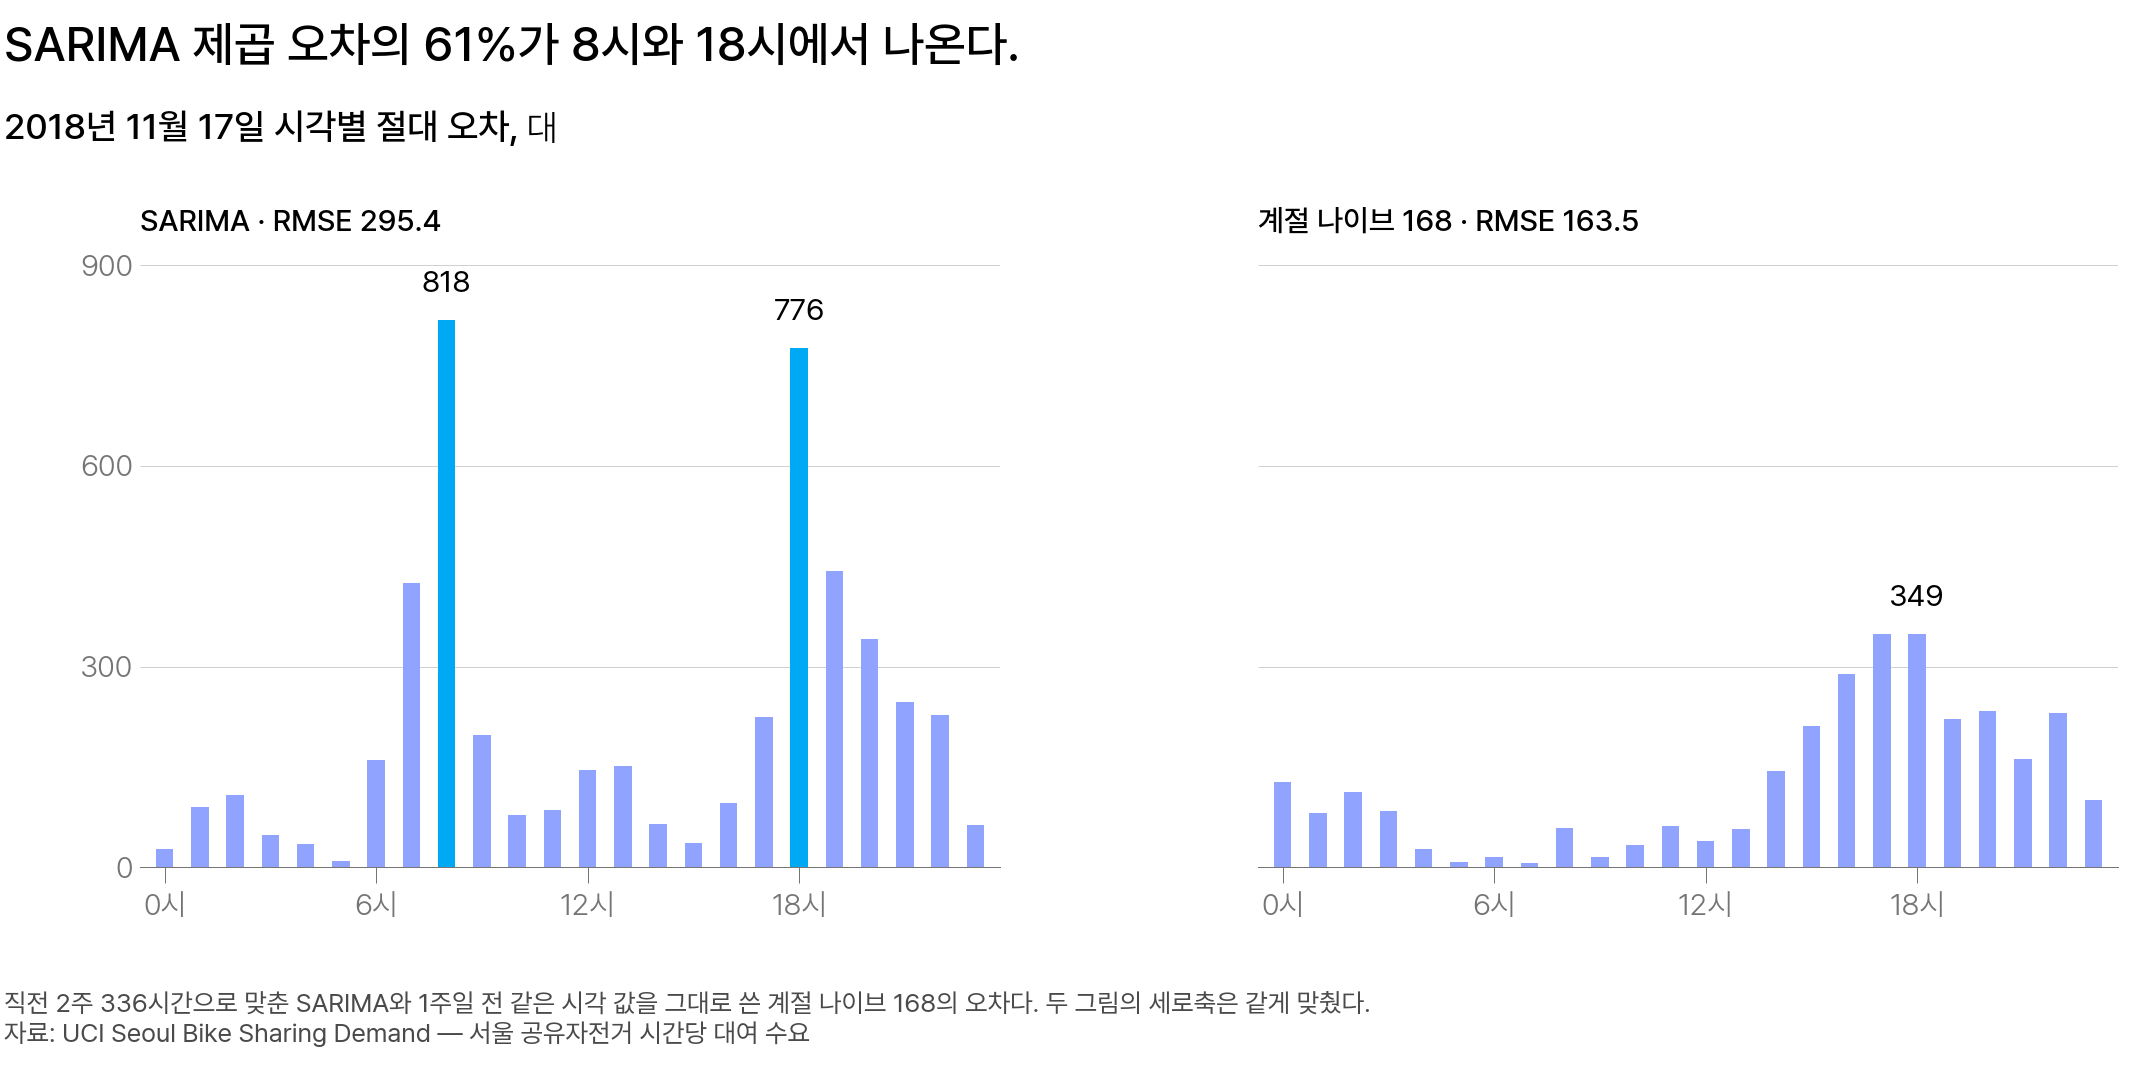

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 같은 토요일 24시간의 시각별 절대 오차. SARIMA 는 8시와 18시의 오차가 가장 크고, 계절 나이브 168 은 가장 크게 빗나간 시각도 349대다</em></p>

**결론**

- 배차 숫자는 SARIMA 가 아니라 계절 나이브 168 에서 가져옵니다.
- 11월 17일 토요일 24시간의 평균 제곱근 오차(RMSE)는 SARIMA 가 295.4대입니다. 계절 나이브 168 은 163.5대입니다. 실습의 검증 168시간(11월 17～23일)에서도 386.08대와 205.25대로 계절 나이브 168 이 작습니다.
- 계절 항 2개를 더하면 같은 학습 1,848시간에서 AIC 가 25,209.34 에서 24,502.69 로 706.65 내려갑니다. 그래도 검증 168시간 RMSE 는 2일차 차수 (1,0,1)(0,1,0,24) 의 271.22대에서 386.08대로 커집니다. AIC 는 한 시간 뒤를, 검증 오차는 1～168시간 뒤를 내리 맞힌 결과이기 때문입니다.
- 실습 1,848시간 모형은 잔차 진단을 통과하지 못합니다. 시차 24 Ljung-Box 검정의 p 값이 3.16e-47 로 0.05 보다 작습니다. 남은 규칙은 요일 차이이고, 1주일 전 같은 시각 잔차와의 자기상관이 0.386 입니다. 이 요일 차이는 한계로 적습니다.
- 실습 1,848시간 모형이 검증 168시간에 낸 95% 예측구간은 17일 0시가 767대로 가장 짧습니다. 가장 긴 23일 13시는 1,629대로 2.12배입니다. 위 첫째 그림은 직전 336시간으로 적합한 모형이라 구간 길이가 이와 다릅니다. 기준값은 당일 아침 재배치가 감당할 수 있는 빗나감으로 정합니다. 구간 길이가 기준값보다 짧은 시각은 확신, 나머지는 보류로 적습니다. 확신은 금요일에 대수를 확정할 시각이고, 보류는 당일 아침 실측을 보고 다시 정할 시각입니다.

**기억할 식·지표**

$$
\hat{y}_{t+h} \pm 1.96 \times \sigma_h
$$

- $\hat{y}_{t+h}$ : 학습을 끝낸 시각(예측 원점)에서 $h$시간 뒤의 점 예측입니다
- $\sigma_h$ : $h$시간 뒤 예측 오차가 흔들리는 크기입니다. 미래 값은 아직 없으니 적합 구간의 잔차로 어림합니다
- $1.96$ : 명목 포함률(구간이 실측을 담도록 정한 비율) 95% 에 맞춰 곱하는 수입니다

구간 길이는 상한 − 하한 $= 2 \times 1.96 \times \sigma_h$ 입니다. 검증 구간의 실측이 하한 이상 상한 이하인 시각의 비율은 실제 포함률이라 부르고, 명목 포함률과 견줍니다.

$$
Q_{\text{LB}} = T(T+2) \sum_{k=1}^{L} \frac{\hat{\rho}_k^2}{T-k}
$$

- $\hat{\rho}_k$ : 잔차의 시차 $k$ 자기상관입니다
- $T$ : 잔차 개수입니다
- $L$ : 모아 보는 마지막 시차입니다

Ljung-Box 검정의 귀무가설은 「잔차가 백색잡음이다」입니다. 그래서 p 값이 0.05 보다 작으면 잔차에 규칙이 남았다는 뜻입니다.

**쓰는 코드**

- `res = SARIMAX(demand, order=(1, 0, 1), seasonal_order=(1, 1, 1, 24)).fit(disp=False)`: 비계절 차수 (1, 0, 1) 과 계절 차수 (1, 1, 1, 24) 로 SARIMA 를 적합합니다
- `fc = res.get_forecast(steps=len(y_valid))` 뒤 `fc.conf_int(alpha=0.05)`: 95% 예측구간의 하한과 상한입니다. 이름은 `conf_int` 이지만 계산하는 것은 예측구간입니다
- `acorr_ljungbox(res.resid[24:], lags=[24], model_df=4)`: 잔차 진단입니다. 앞 24시각은 뺄 24시간 전 값이 없어 제외하고, `model_df=4` 는 추정한 계수 4개입니다

**흔한 실수**

- 베이스라인을 `df["demand"].shift(24)` 로 만드는 실수입니다. 16일 23시에서 18일 8시(33시간 뒤)를 예측하면, 16일 23시에는 아직 없는 17일 8시 실측이 들어갑니다. 168시간 뒤로 옮기면 168개 모두 16일 23시 이전 값입니다.
- Ljung-Box p 값 3.16e-47 을 「0 에 가까우니 자기상관이 없다」로 읽는 실수입니다. 귀무가설이 「잔차가 백색잡음이다」라, 작은 p 값은 잔차에 규칙이 남았다는 뜻입니다. p 값이 커서 통과해도 예측이 정확하다는 뜻은 아닙니다.

**다시 볼 곳**

- 3일차 이론 「2. 잔차 진단과 Ljung-Box 검정」
- 3일차 이론 「3. 예측구간 — 점 예측 옆에 적는 범위」
- 3일차 이론 「4. 토요일 24시간 예측은 베이스라인보다 나은가」

## 4. 4일차 — 예측 평가와 교차 검증

**결정 질문** 둘째 날 ARIMA 와 셋째 날 SARIMA 를 운영에 써도 될지, 한 주의 RMSE 가 아니라 무엇으로 정할까요?

한 주만 채점한 RMSE 는 그 주 하나의 결과라, 채점하는 주를 바꾸면 순위가 바뀔 수 있습니다. 그래서 학습을 끝내는 시각인 예측 원점(forecast origin)을 1주씩 옮기며 여러 번 채점하고 평균 RMSE 로 비교합니다. 아래 첫째 그림처럼 원점이 늦을수록 학습에 쓰는 관측이 늘고, 채점 시각은 언제나 학습 구간 뒤에 있습니다. 이 순서를 지키는 분할이 아래 둘째 그림의 `TimeSeriesSplit` 입니다.

예를 들어 모형 A 의 RMSE 가 첫 주 250대, 나머지 네 주 450대이면 평균은 $(250 + 4 \times 450) / 5 = 410$대입니다. 다섯 주 모두 380대인 모형 B 는 첫 주만 보면 A 보다 나쁘고, 평균으로 보면 A 보다 낫습니다.

<img src="https://otexts.com/fpp3/fpp_files/figure-html/cv1-1.png" width="640" height="300" alt="점이 가로로 늘어선 20개 행. 행마다 왼쪽 파란 점은 학습 관측, 주황 점 하나는 채점 시각, 오른쪽 회색 점은 쓰지 않은 관측이고, 아래 행일수록 파란 점이 하나씩 늘어난다"/>
<p align="center"><em>▲ 시계열 교차 검증의 분할 20개. 한 행이 한 분할이고, 파란 점은 학습 관측, 주황 점은 채점 시각, 회색 점은 쓰지 않은 관측이다. 아래 행일수록 예측 원점이 늦다 (출처: Hyndman·Athanasopoulos, 『Forecasting: Principles and Practice』 3판 5.10)</em></p>

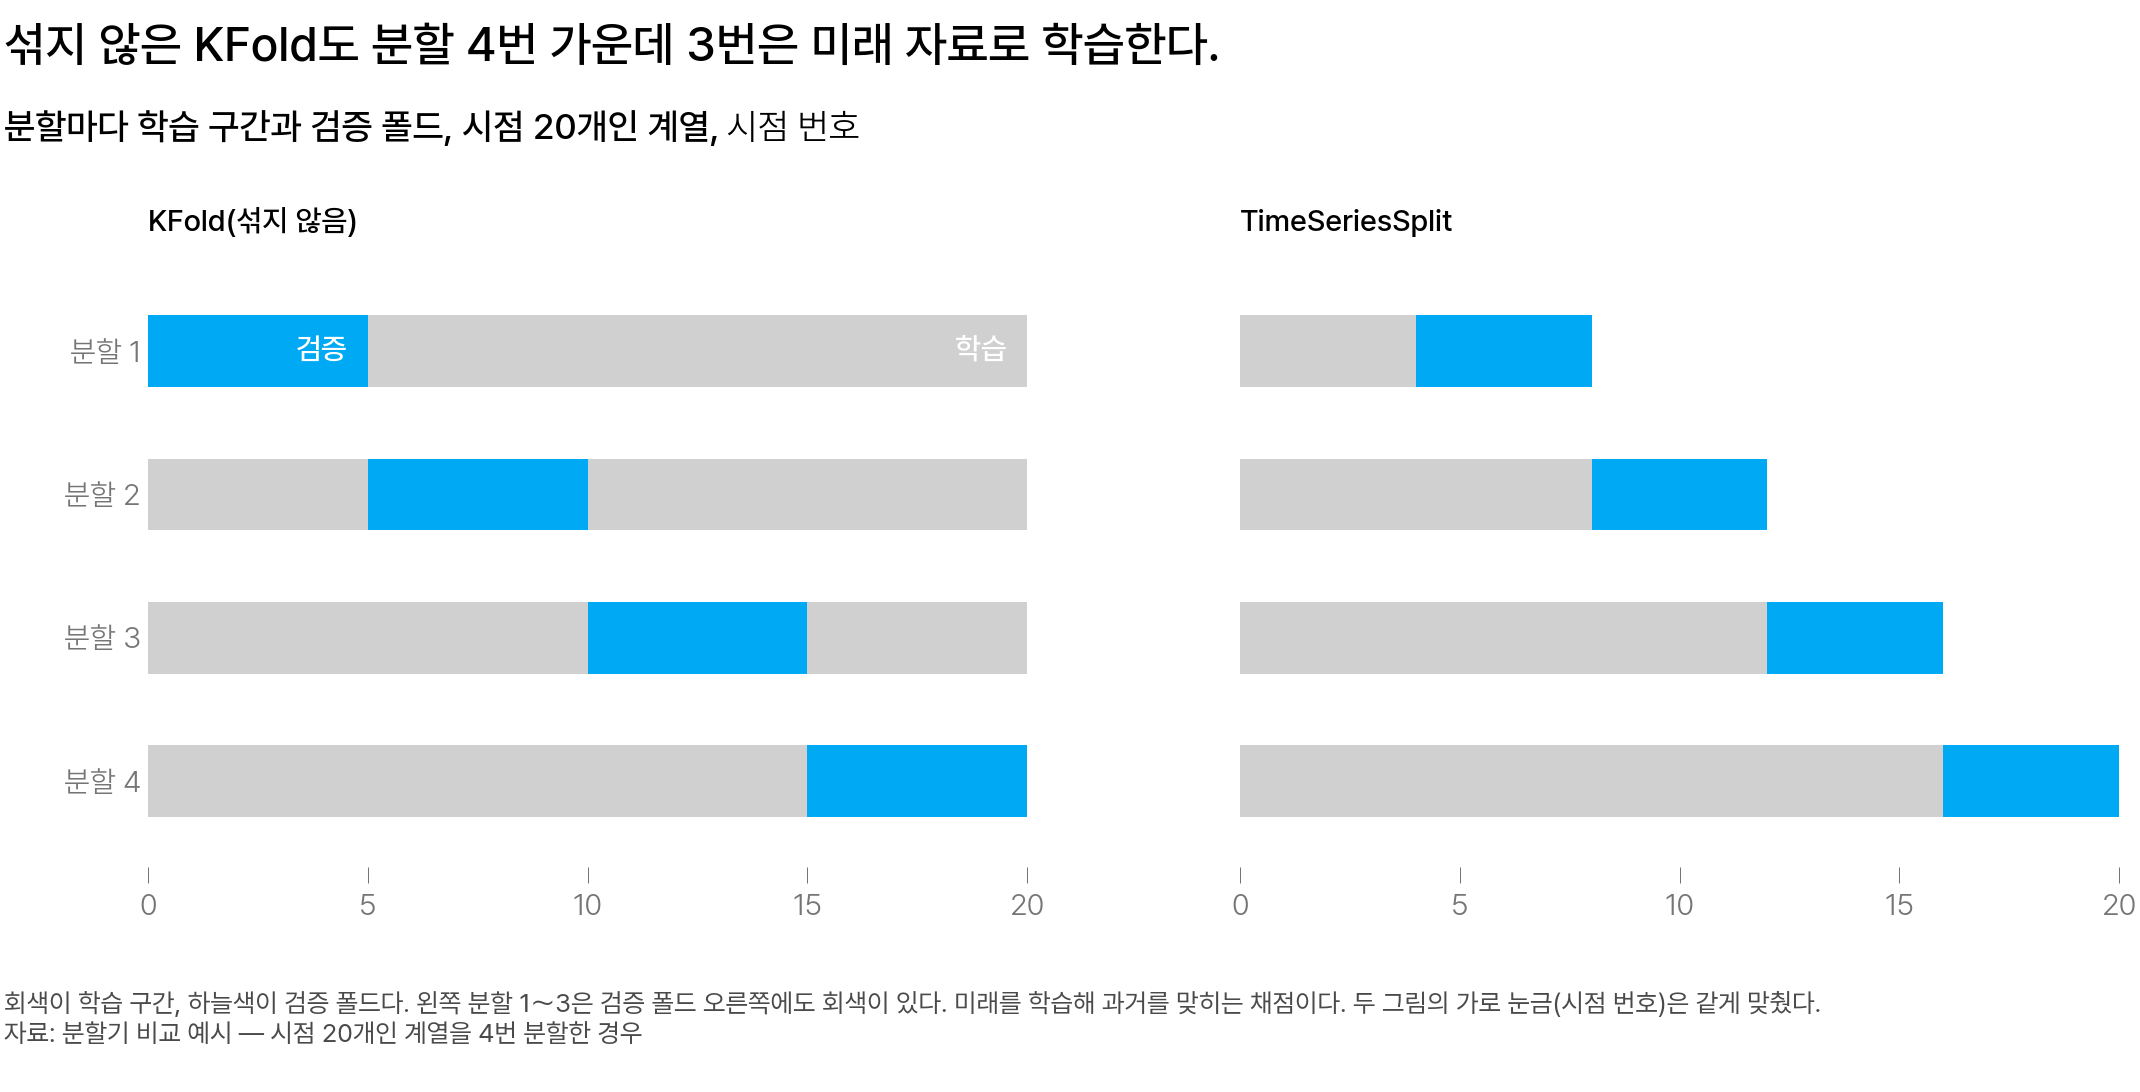

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 시점 20개인 계열을 4번 분할한 두 방식. 회색이 학습 구간, 하늘색이 검증 폴드이고, 섞지 않은 KFold 는 분할 1～3 에서 검증 폴드 오른쪽에도 학습 구간이 있다</em></p>

**결론**

- 예측 원점 5개의 평균 RMSE 를 베이스라인 계절 나이브 168 과 비교해 정합니다. 10월 19일～11월 16일의 금요일 23시 5개마다 그 뒤 168시간을 채점합니다.
- 둘째 날 ARIMA 는 (1,0,1)(0,1,0,24), 셋째 날 SARIMA 는 (1,0,1)(1,1,1,24) 입니다. 두 모형은 아직 운영에 쓰지 않습니다. 원점 5개 평균 RMSE 가 셋째 날 SARIMA 385.06대, 둘째 날 ARIMA 425.68대입니다. 둘 다 베이스라인 계절 나이브 168 의 363.55대보다 큽니다.
- 순위는 한 주가 아니라 원점 5개 평균으로 정합니다. 11월 16일 원점에서는 둘째 날 ARIMA 가 271.22대로 셋째 날 SARIMA 의 386.08대보다 작았습니다. 5개 평균에서는 순위가 반대입니다.
- 서울 공유자전거의 대표 지표는 RMSE 입니다. 한 시각에 1,380대가 모자란 월요일 8시 같은 큰 오차 한 번이 배차에서 가장 비쌉니다.
- 백분율이 필요하면 MAPE 대신 WAPE(오차 절댓값의 합 ÷ 실측의 합)로 적습니다. MAPE 는 시각마다 오차를 실측으로 나눈 비율의 평균이라 실측이 작은 시각 하나가 값을 키웁니다. 자정 7개 시각의 MAPE 78.8% 가운데 59.2%p 가 실측 119대인 한 시각에서 나옵니다. 같은 7개 시각의 WAPE 는 36.9% 입니다.

**기억할 식·지표**

$$
\text{RMSE} = \sqrt{\frac{1}{n}\sum_{t=1}^{n} e_t^{\,2}}, \qquad e_t = y_t - \hat{y}_t
$$

- $e_t$ : 시각 $t$ 의 실측 $y_t$ 에서 예측을 뺀 오차입니다
- $n$ : 채점한 시각 수입니다. 예측 원점 하나에 168 입니다

오차를 제곱해 평균한 뒤 제곱근을 씌워 큰 오차에 무게를 더 주고, 단위는 대입니다.

$$
\text{MASE} = \frac{\text{MAE}}{Q}
$$

- $\text{MAE}$ : 후보가 채점 구간에서 받은 평균 절대 오차입니다
- $Q$ : 학습 구간에서 하루 전 같은 시각 값($m = 24$)이 빗나간 평균 295.40대입니다

MASE 가 1 보다 작으면 하루 전 같은 시각 값이 학습 구간에서 낸 평균 오차(295.40대)보다 덜 빗나간 것입니다. 같은 채점 구간에서 나이브 규칙을 이겼다는 뜻은 아닙니다. 계열이 하나라 $Q$ 가 고정되면 MASE 순위는 MAE 순위와 같습니다. 그래서 큰 오차에 무게를 더 주는 RMSE 와 순위가 엇갈릴 수 있습니다.

**쓰는 코드**

- `TimeSeriesSplit(n_splits=5, test_size=168).split(X_cv)`: 검증 폴드가 168시간인 분할 5개를 시간 순서대로 만듭니다
- `df["demand"].shift(168)`: 베이스라인 계절 나이브 168 의 예측입니다
- `StandardScaler().fit(y_all[:1848])`: 스케일러를 학습 구간 1,848시간으로만 fit 합니다

**흔한 실수**

- `KFold(shuffle=True)` 로 채점한 더 작은 평균 RMSE 를 보고하는 실수입니다. 같은 선형회귀로 같은 5주를 채점하면 `KFold(shuffle=True)` 는 약 308대, `TimeSeriesSplit` 은 약 336대입니다. 약 308대는 채점 시각보다 뒤의 시각을 학습에 쓴 값이라, 보고할 값은 약 336대입니다.
- 스케일러를 전체 자료로 한 번 fit 해 모든 분할에 쓰는 실수입니다. 채점하는 주와 그 뒤의 값까지 평균에 들어가는 데이터 누수(채점 시각보다 미래의 정보가 학습에 들어가는 일)입니다. 분할 1 의 학습 폴드로 fit 한 기온 평균은 18.79 °C 로, 11월까지 포함한 전체 평균 14.92 °C 와 다릅니다.

**다시 볼 곳**

- 4일차 이론 「3. 대표 지표 RMSE」
- 4일차 이론 「4. 시계열 교차 검증」
- 4일차 이론 「5. 전처리와 데이터 누수」

## 5. 5일차 — Prophet · 추세 변화점 · 외생 변수

**결정 질문** Prophet 을 운영 예측에 써도 될까요? 쓴다면 어떤 구성이어야 할까요?

Prophet 구성은 바꿀 때마다 학습에 쓰지 않은 기간의 오차를 베이스라인과 견줘 확인합니다. 예를 들어 베이스라인의 RMSE 가 360대일 때 새 구성이 350대면 10대 낮아 후보가 됩니다. 370대면 10대 높아 베이스라인을 그대로 씁니다. 아래 첫째 그림의 푸리에 차수는 일간 계절성을 그리는 사인·코사인 쌍의 수이고, 기본값은 4 입니다.

조건부 계절성은 하루 곡선을 평일과 주말로 나눠 따로 둡니다. 아래 둘째 그림에서 8시에 더하는 값은 평일 곡선 +214.2대, 주말 곡선 −409.1대로 방향이 반대입니다. 그래서 요일 공통 하루 곡선 하나로는 평일과 주말의 8시를 함께 맞히지 못합니다.

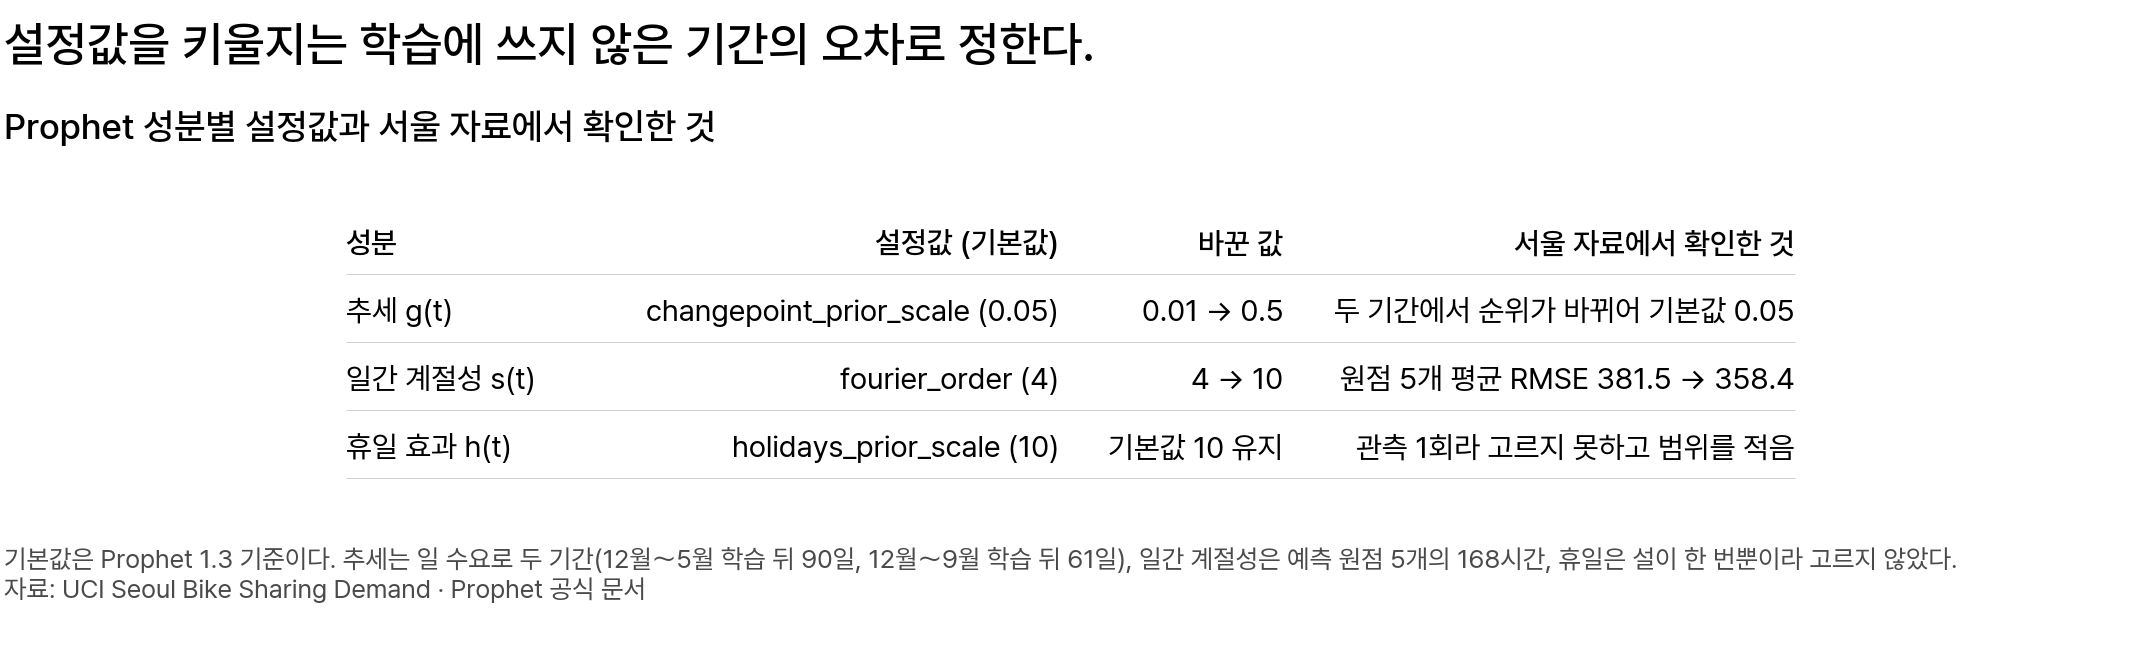

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ Prophet 성분마다 바꿀 수 있는 설정값과 서울 공유자전거에서 확인한 것. 일간 계절성의 푸리에 차수를 4 에서 10 으로 키우자 예측 원점 5개 평균 RMSE 가 381.5 에서 358.4 로 내려갔다</em></p>

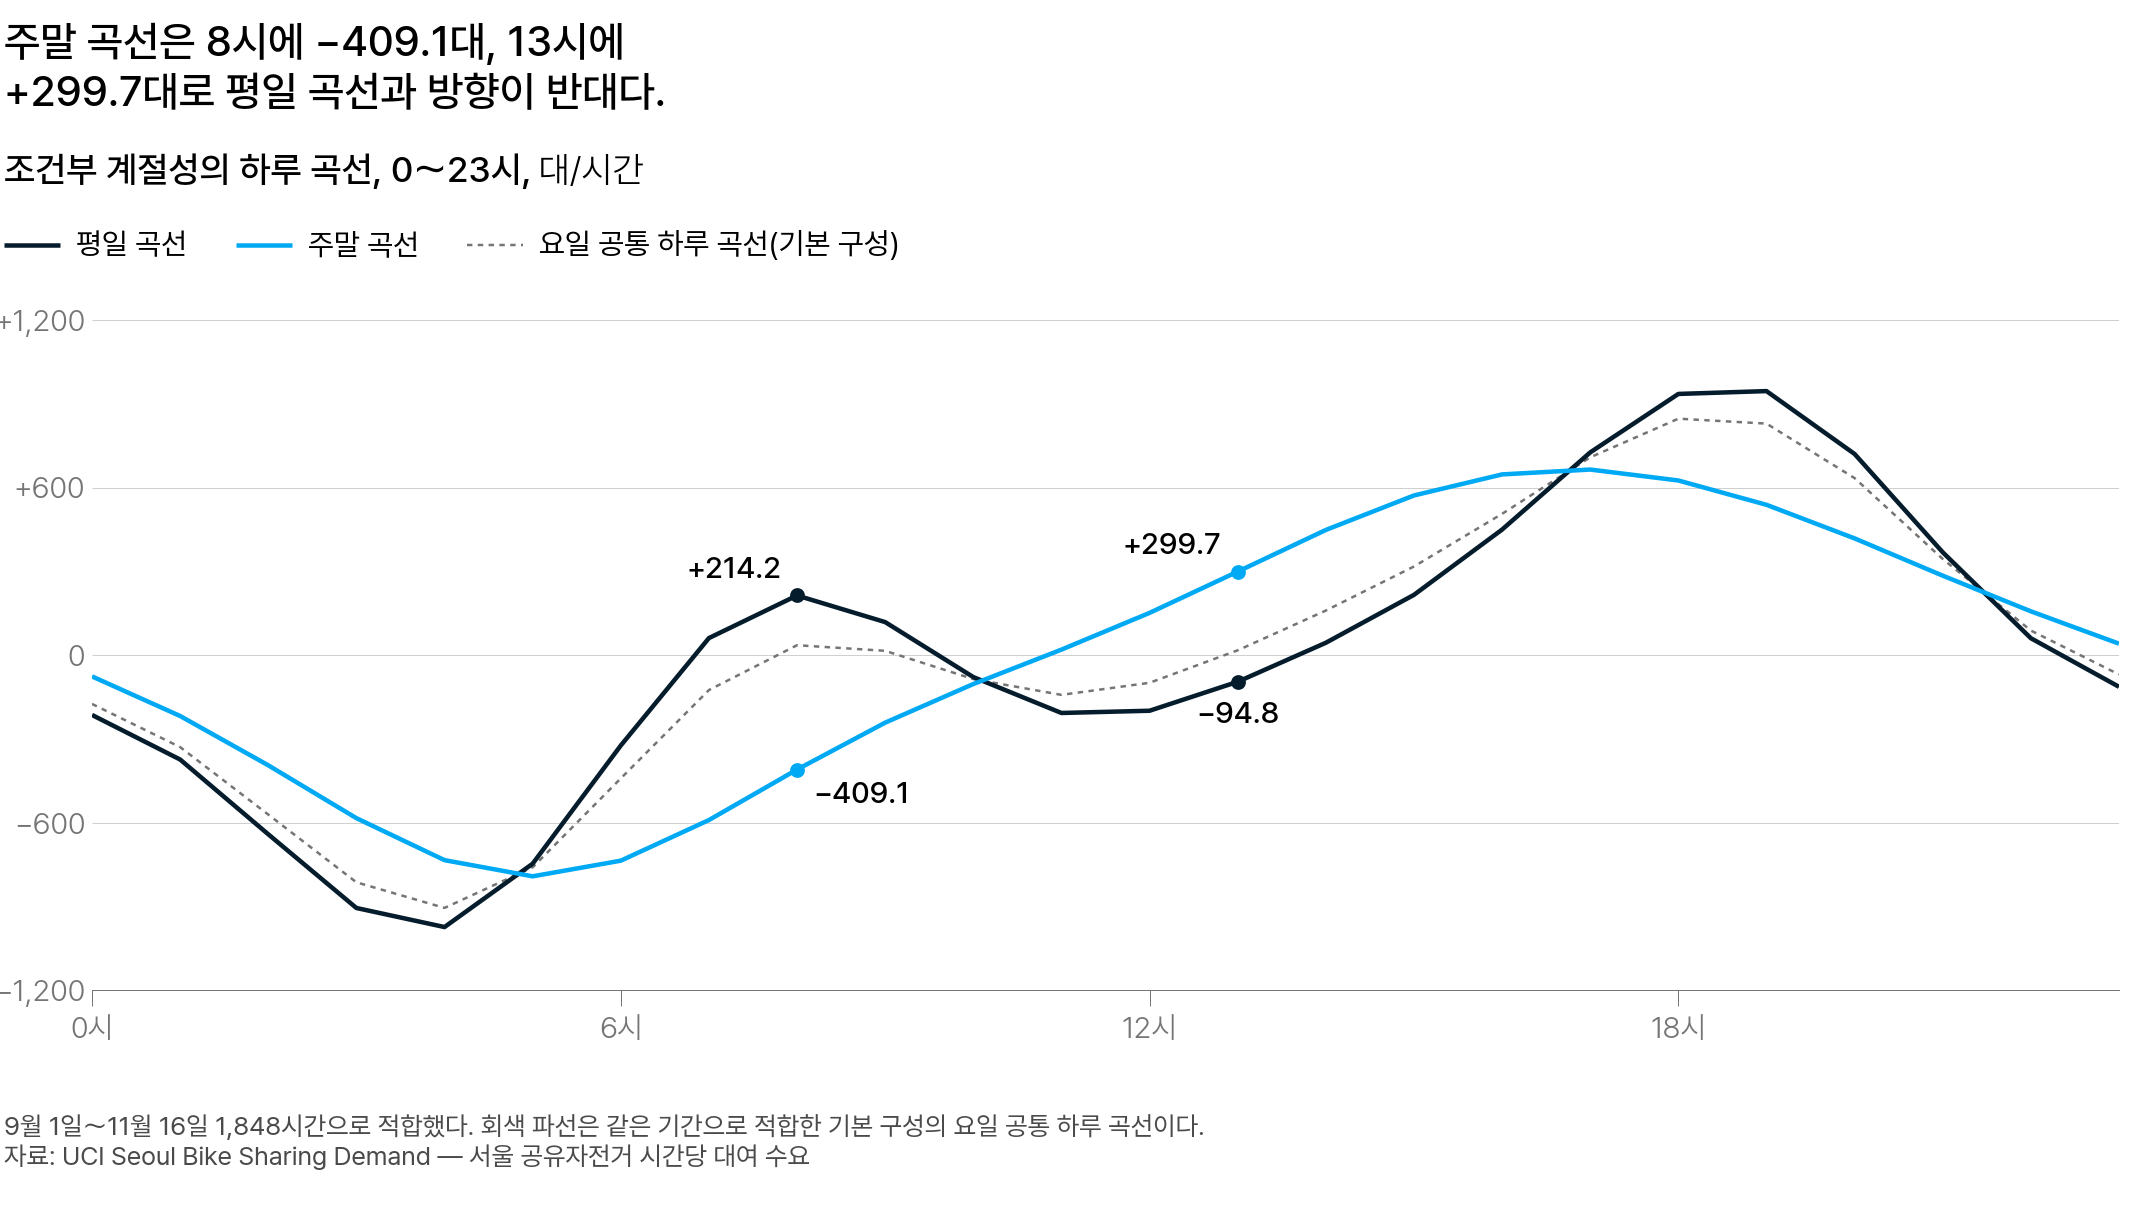

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 조건부 계절성의 평일 곡선은 남색, 주말 곡선은 하늘색, 기본 구성의 요일 공통 하루 곡선은 회색 파선이다. 13시에는 평일 곡선이 −94.8대, 주말 곡선이 +299.7대다</em></p>

**결론**

- 운영 예측은 베이스라인(계절 나이브 168)으로 둡니다. Prophet 기본 구성의 예측 원점 5개 평균 RMSE 는 381.47대로, 베이스라인 363.55대보다 17.92대 높습니다.
- 다음 후보는 RMSE 가 베이스라인보다 낮은 세 구성입니다. 조건부 계절성은 352.10대, 푸리에 차수를 4 에서 10 으로 키운 구성은 358.41대, 곱셈 계절성은 359.32대입니다.
- 세 후보 모두 MASE 는 베이스라인보다 높습니다. MASE 는 MAE 를 고정된 $Q$ 로 나눈 값이라, 큰 오차 몇 번은 줄였지만 시각마다의 평균 오차는 베이스라인보다 크다는 뜻입니다. 두 지표의 답이 엇갈리고 큰 오차는 드문 날 몇 개가 정하므로, 테스트 구간(11월 24～30일)에서 한 번 채점한 뒤 정합니다.
- 날씨 열은 이번 검증 구간에 더하지 않습니다. 기온·강수를 더하면 검증 168시간 RMSE 가 310.34대에서 340.16대로 커집니다. 예보 대신 실측 날씨를 대입한 사후 예측인데도 커진 값입니다.
- 일 수요 365일 추세의 변화량이 큰 변화점은 연간 계절성을 포함하면 0곳, 제외하면 7곳입니다. 그래서 변화점 개수를 보고할 때는 모형에 포함한 성분을 함께 적습니다.

**기억할 식·지표**

$$
y(t) = g(t) + s(t) + h(t) + \varepsilon_t
$$

- $g(t)$ : 추세입니다. 변화점에서 기울기가 바뀌는 직선입니다
- $s(t)$ : 계절성입니다. 시간당 자료에서는 일간·주간 계절성의 합입니다
- $h(t)$ : 휴일 효과입니다. 공휴일이 아닌 날은 0 입니다
- $\varepsilon_t$ : 세 성분이 설명하지 못하고 남은 오차항입니다

구성을 비교하는 지표는 4일차 카드의 RMSE 와 MASE 입니다.

**쓰는 코드**

- `Prophet(yearly_seasonality=False, weekly_seasonality=True, daily_seasonality=True, holidays=holidays_one, uncertainty_samples=0)`: 기본 구성입니다. 연간 계절성을 제외하고 주간·일간 계절성과 휴일 데이터프레임(공휴일 18일)을 포함합니다
- `m.add_regressor(r)`: 외생 변수 열을 항으로 더합니다. 학습 표와 예측 표 양쪽에 그 열이 있어야 합니다
- `df["demand"].shift(168)`: 운영 예측으로 내는 베이스라인입니다

**흔한 실수**

- 80% 예측구간이 실측을 덜 담았다고 `interval_width` 부터 높이는 실수입니다. 11월 17일 80% 구간의 실제 포함률은 50% 였고, 벗어난 시각은 모두 하한 아래였습니다. 이렇게 한쪽으로만 벗어나면 예측선이 치우친 것이라 구성부터 고칩니다. 위아래로 고르게 벗어났을 때만 명목 포함률을 높입니다.
- 외생 변수를 수요와의 상관 크기로 고르는 실수입니다. 금요일 23시 예측 원점에서 다음 168시간 값을 채울 수 없는 열(대여소 반납 건수·공유자전거 앱 접속자 수)은 더할 수 없습니다. 예보로 채울 수 있는 기온도 예측 기간의 값이 학습 범위 밖이면 오차를 키웁니다. 검증 168시간 가운데 101시간이 학습 기온의 5백분위수 6.2도보다 추웠습니다. 5백분위수는 크기순으로 정렬한 값에서 아래로부터 5% 지점에 있는 값입니다.

**다시 볼 곳**

- 5일차 이론 「7. 외생 변수: 미래에도 값이 있는 변수」
- 5일차 이론 「8. 예측구간 — 명목 포함률과 실제 포함률」
- 5일차 이론 「9. 예측 원점 5개 비교와 Prophet 구성 순서」

## 6. 이상 탐지 — 잔차 강건 Z 와 임계값

**이상 탐지(anomaly detection)** 는 잔차가 평소보다 얼마나 벗어났는지 계산하는 일입니다. 평소 값은 같은 시각 잔차의 중앙값이고, 벗어난 크기는 평소 오르내림(MAD)의 몇 배로 나타냅니다. 그 값이 임계값을 넘은 시각을 **이상으로 탐지**합니다.

**결정 질문** 계획표의 `이상` 열에는 어느 시각을 참으로 적을까요?

**결론**

- 기댓값은 **보정 수요**(휴무 시각을 1주일 전 같은 시각 값으로 채운 수요)의 1주일 전 같은 시각 값이고, 잔차 $r_t$ 는 실측 − 기댓값입니다.
- 잔차 강건 Z 의 절댓값이 임계값을 넘는 시각이 참입니다. **기준 구간**은 중앙값·MAD 와 임계값을 정하는 앞 구간입니다. 임계값은 3.5 에서 시작합니다. **오탐**(false positive)은 정상 시각을 이상으로 탐지한 것입니다. 기준 구간의 하루 오탐 수가 운영팀과 정한 상한 안에 드는 가장 작은 값을 고릅니다.
- 계획표 아래에는 고른 임계값과 그 임계값의 기준 구간 하루 오탐 수를 근거로 적습니다.

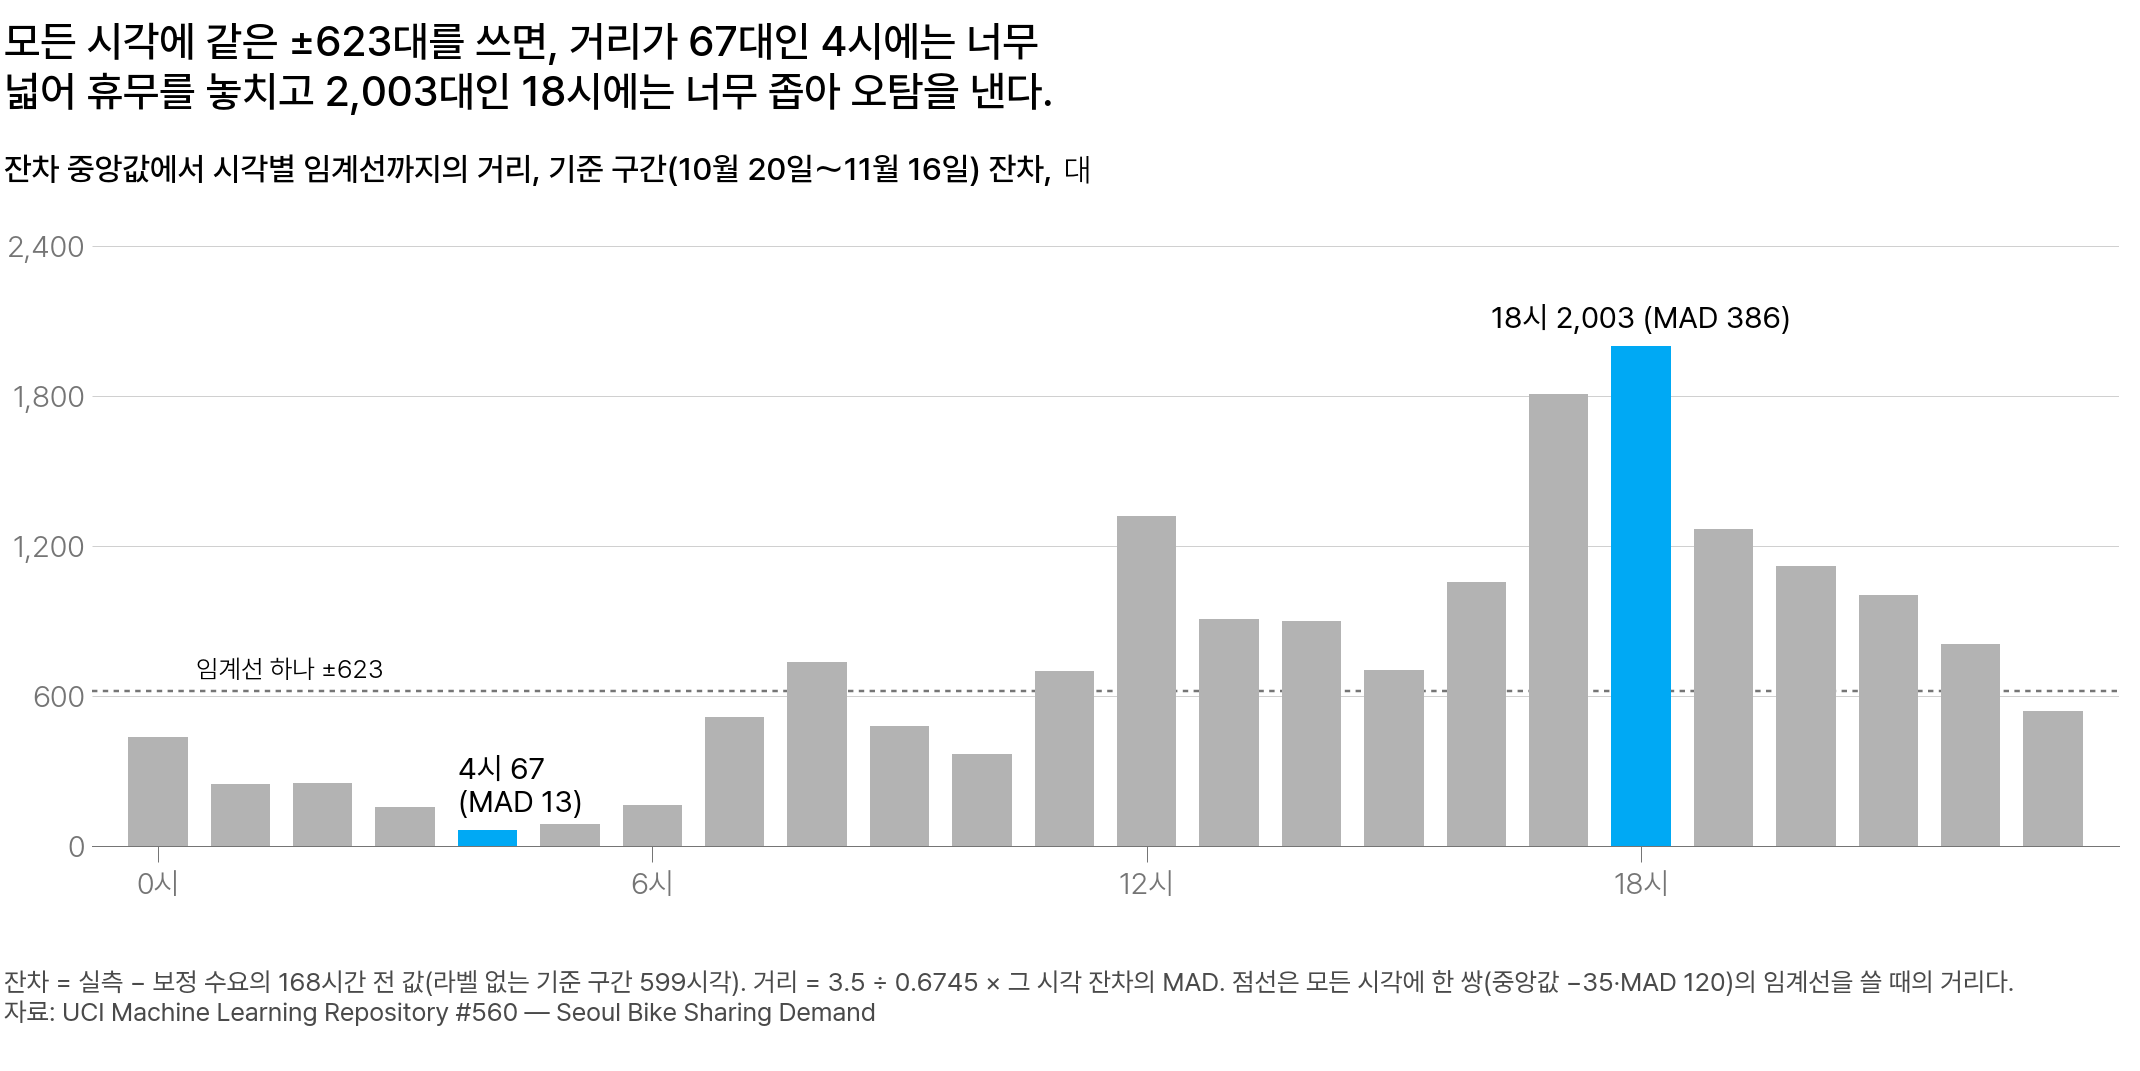

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 임계선(잔차 강건 Z 의 절댓값이 3.5 인 잔차)이 기준 구간(10월 20일～11월 16일) 잔차의 중앙값에서 떨어진 거리. 4시 67대, 18시 2,003대로 시각마다 다르고, 점선은 모든 시각에 임계선 한 쌍을 쓸 때의 거리 623대다</em></p>

**기억할 식·지표**

$$
z_t = 0.6745 \times \frac{r_t - \operatorname{med}_h}{\operatorname{MAD}_h}
$$

- $\operatorname{med}_h$ : 기준 구간에서 정답 라벨(휴무·시간당 강수 10mm 이상)이 없는 잔차를 시각 $h$ 로 묶은 중앙값입니다
- $\operatorname{MAD}_h$ : 그 잔차들이 중앙값에서 떨어진 거리의 중앙값입니다
- $0.6745$ : MAD 를 0.6745 로 나누면(약 1.48배) 정규분포의 표준편차와 같은 크기가 됩니다. 식은 이 나눗셈을 분자에 0.6745 를 곱하는 형태로 적었습니다

중앙값·MAD 는 이상이 포함돼도 거의 바뀌지 않아 평균·표준편차 대신 씁니다.

**쓰는 코드**

- `RESID = CNT - DEM.shift(168)`: 잔차
- `z = 0.6745 * (RESID - HOUR.map(MED_H)) / HOUR.map(MAD_H)`: 잔차 강건 Z
- `z.abs() > 3.5`: 참이면 이상으로 탐지

**흔한 실수**

- 원본 대여 수로 기댓값을 만들면 휴무 1주일 뒤 기댓값이 0 이 되어 평범한 수요도 이상으로 탐지됩니다.
- 계획표 168시각에서 이상으로 탐지된 시각 수를 보고 임계값을 고르지 않습니다. 복습 프로젝트 미션 2 의 기준 구간은 예측 원점 앞 4주(10월 20일～11월 16일)입니다.

**다시 볼 곳**

- 복습 프로젝트 미션 2(다음 주 운영 계획표)의 8시 계산 예

## 7. 모듈 결정 규칙 한눈에

다섯 날의 결론과 이상 탐지 규칙을 상황별로 모았습니다. 근거가 되는 수는 오른쪽 열에 적은 날의 카드에 있습니다.

| 이런 상황이면 | 이렇게 합니다 | 카드 |
|---|---|---|
| 계절 주기를 정할 때 | 후보 주기마다 계절성 강도를 구해 큰 쪽을 계절 주기 $m$ 으로 둡니다 | 1일차 |
| 정상성을 확인할 때 | ADF 와 KPSS 를 함께 적용하고, 무엇을 기각했는지 결론에 적습니다 | 1일차 |
| 계열이 비정상일 때 | 자기상관이 주기의 배수에서 커지면 계절차분, 평균이 한 방향으로 옮겨 가면 1차 차분을 1회 합니다 | 1일차 |
| ARIMA 차수를 고를 때 | 자기상관 그림으로 후보를 좁히고, 같은 $d$ 안에서 AIC 가 가장 낮은 차수를 고릅니다. 차이가 2 이하면 항이 적은 쪽을 고릅니다 | 2일차 |
| 모형을 예측에 쓰기 전 | 잔차에 Ljung-Box 검정을 적용하고, p 값이 0.05 보다 작으면 남은 규칙을 한계로 적습니다 | 3일차 |
| 점 예측 옆에 범위를 적을 때 | 95% 예측구간을 적고, 구간 길이가 기준값보다 짧은 시각만 확신으로 적습니다 | 3일차 |
| 새 모형을 운영에 쓸지 정할 때 | 예측 원점 5개 평균 RMSE 가 계절 나이브 168 보다 작으면 후보로 두고, 테스트 구간에서 한 번 채점한 뒤 씁니다 | 3·4·5일차 |
| 교차 검증과 전처리를 할 때 | `TimeSeriesSplit` 으로 나누고, 스케일러는 분할마다 학습 폴드로만 fit 합니다 | 4일차 |
| 외생 변수를 더하려 할 때 | 예측 기간의 값을 채울 수 있고 학습 범위 안인지 본 뒤, 검증 오차로 정합니다 | 5일차 |
| 이상으로 탐지할 시각을 정할 때 | 보정 수요의 1주일 전 값을 뺀 잔차에 시각별 강건 Z 를 계산하고, 임계값은 기준 구간에서 고릅니다 | 이상 탐지 |